# Synthetic Results Analysis

This notebook analyzes outputs produced by `scripts/run_synthetic_results.py`: multi-seed metrics, global curves, patient-specific surfaces, confidence intervals, and non-parametric statistical tests.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src").exists():
    for parent in Path.cwd().parents:
        if (parent / "src").exists():
            PROJECT_ROOT = parent
            break
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.analysis.results_analysis import (
    available_metrics,
    export_analysis_tables,
    load_global_curves,
    load_patient_curves,
    load_patient_metadata,
    load_results_metrics,
    make_publication_table,
    metric_spec_available,
    non_oracle_methods,
    plot_global_curves,
    plot_method_metrics_ci_grid,
    plot_patient_surface_from_table,
    plot_patient_surface_gallery_from_table,
    print_statistical_tables,
    run_statistical_tests,
    save_figure,
    set_plot_theme,
    statistical_test_table,
    summarize_metric_ci,
)

set_plot_theme(style="whitegrid", context="notebook", font_scale=1.0)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 260)
pd.set_option("display.expand_frame_repr", False)
PROJECT_ROOT
# Force white background in rendered and saved figures.
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["savefig.facecolor"] = "white"
plt.rcParams["savefig.edgecolor"] = "white"


## Editable Configuration

Set `RESULTS_DIR` to the output directory generated by `run_synthetic_results.py`. Method names are normalized when curve tables are loaded, so names such as `Weighted_PMMR` become `Weighted PMMR`.

In [55]:
from src.analysis.plot_styles import METHOD_ORDER, METHOD_LABELS, METHOD_COLORS

RESULTS_DIR = PROJECT_ROOT / "results" / "wu2024_article"

# Set to None to analyze all available seeds. The range below keeps seeds 1..10 inclusive.
SEEDS_TO_ANALYZE = list(range(1, 11))
SEED_LABEL = "all_seeds" if SEEDS_TO_ANALYZE is None else f"seeds_{min(SEEDS_TO_ANALYZE)}_{max(SEEDS_TO_ANALYZE)}"
ANALYSIS_DIR = RESULTS_DIR / "analysis" / SEED_LABEL
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

DEFAULT_SPLIT = "test"
ALPHA = 0.05
CONFIDENCE = 0.95

# Optional clipping for RMSE figure y-axes so extreme outliers (e.g., NMMR-U) do not hide other methods.
RMSE_YMAX_EXCLUDE_FAMILIES = ["NMMR-U", 'Weighted NMMR-U']
RMSE_YMAX_MARGIN_RATIO = 0.08




METHOD_LINESTYLES = {
    "PMMR": "-",
    "Weighted PMMR": "--",
    "NMMR-U": "-",
    "Weighted NMMR-U": "--",
    "NMMR-V": "-",
    "Weighted NMMR-V": "--",
    "NMMR": "-.",
    "Weighted NMMR": ":",
    "KPV": "-",
    "Weighted KPV": ":",
    "DFPV": "-.",
    "Weighted DFPV": "--",
    "DR-KPV": "--",
    "DR-PMMR conditional": "-.",
    "DR-PMMR marginal": ":",
    "S-Learner": "-",
    "Naive OOSR": "--",
    "Oracle S-Learner": "-.",
    "Oracle Naive OOSR": ":",
}

METRICS_TO_PLOT = [
    "val_regret",
    "factual_mean_rmse",
    "global_rmse",
    "local_rmse",
    "mean_curve_rmse",
    "mean_curve_argmax_abs_error",
    "regret_causal_marginal",
    "policy_mse_causal_marginal",
    "policy_value_causal_marginal",
]

METRIC_LABELS = {
    "val_regret": "Validation regret",
    "factual_mean_rmse": "Factual RMSE",
    "global_rmse": "Counterfactual RMSE",
    "local_rmse": "Local RMSE",
    "mean_curve_rmse": "Mean curve RMSE",
    "mean_curve_argmax_abs_error": "Argmax absolute error",
    "regret_causal_marginal": "Policy regret",
    "policy_mse_causal_marginal": "Policy MSE",
    "policy_value_causal_marginal": "Policy value",
}

METRIC_DIRECTIONS = {
    "policy_value_causal_marginal": True,
    "policy_value_oracle": True,
    "policy_value_structural": True,
}

NON_SHOWN_MODELS = ['NMMR', 'Weighted NMMR', 'Oracle S-Learner', 'Oracle Naive OOSR']

RESULTS_DIR, ANALYSIS_DIR

(WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/wu2024_article'),
 WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/wu2024_article/analysis/seeds_1_10'))

## Load Result Tables

The optional `SEEDS_TO_ANALYZE` selector is applied immediately after loading. All summaries, plots, and statistical tests below use only this subset.


In [3]:
metrics_df = load_results_metrics(RESULTS_DIR)
if SEEDS_TO_ANALYZE is not None:
    seed_set = {int(seed) for seed in SEEDS_TO_ANALYZE}
    metrics_df = metrics_df[metrics_df["seed"].astype("Int64").isin(seed_set)].copy()

global_curves_df = load_global_curves(RESULTS_DIR, seeds=SEEDS_TO_ANALYZE)
patient_curves_df = load_patient_curves(RESULTS_DIR, seeds=SEEDS_TO_ANALYZE)
patient_metadata_df = load_patient_metadata(RESULTS_DIR, seeds=SEEDS_TO_ANALYZE)

# Filtering models listed in NON_SHOWN_MODELS affects every downstream plot/table using these dataframes.
hidden_methods = {str(method) for method in NON_SHOWN_MODELS}
if hidden_methods:
    metrics_df = metrics_df[~metrics_df['method'].astype(str).isin(hidden_methods)].copy()
    global_curves_df = global_curves_df[~global_curves_df['method'].astype(str).isin(hidden_methods)].copy()
    patient_curves_df = patient_curves_df[~patient_curves_df['method'].astype(str).isin(hidden_methods)].copy()

selected_seeds = sorted(metrics_df["seed"].dropna().astype(int).unique().tolist())
print(f"selected seeds: {selected_seeds}")
print(f"analysis_dir: {ANALYSIS_DIR}")
print(f"metrics: {metrics_df.shape}")
print(f"global_curves: {global_curves_df.shape}")
print(f"patient_curves: {patient_curves_df.shape}")
print(f"patient_metadata: {patient_metadata_df.shape}")
display(metrics_df.head())
display(patient_curves_df[["raw_method", "method"]].drop_duplicates().sort_values("method"))


selected seeds: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
analysis_dir: C:\Users\Alex\CODE\optimal_treatment_proximal_inference\weighted_proximal_oosr\results\wu2024_article\analysis\seeds_1_10
metrics: (240, 45)
global_curves: (13260, 10)
patient_curves: (408000, 18)
patient_metadata: (500, 22)


,dataset,seed,split,model_key,method,run_dir,factual_mean_mae,factual_mean_rmse,global_rmse,kpv_lambda1,kpv_lambda2,local_rmse,mean_curve_argmax_abs_error,mean_curve_bias,mean_curve_direct_argmax_abs_error,mean_curve_direct_bias,mean_curve_direct_mae,mean_curve_direct_pred_argmax,mean_curve_direct_rmse,mean_curve_direct_true_argmax,mean_curve_mae,mean_curve_pred_argmax,mean_curve_rmse,mean_curve_true_argmax,observed_rmse,optimal_policy_value,optimal_policy_value_causal_marginal,optimal_policy_value_oracle,optimal_policy_value_structural,policy_mse,policy_mse_causal_marginal,policy_mse_oracle,policy_mse_structural,policy_value,policy_value_causal_marginal,policy_value_oracle,policy_value_structural,pseudo_outcome_iqr,pseudo_outcome_std,regret,regret_causal_marginal,regret_oracle,regret_structural,weight_ess_final,raw_method
16,wu2024_nonadditive,1,test,dfpv,DFPV,results/wu2024_article/runs/seed_0001,2.359332,3.008133,6.955944,NaN,NaN,1.551419,1.266351,0.576001,1.266351,-1.005865,7.302293,1.984534,8.900793,0.718183,5.727379,1.984534,6.585855,0.718183,7.418070,1.061025,1.061025,1.097139,1.103893,1.945490,1.945490,1.977887,1.978659,-4.207550,-4.207550,-4.194532,-4.213690,NaN,NaN,5.268575,5.268575,5.291671,5.317583,NaN,DFPV
17,wu2024_nonadditive,1,test,kpv,KPV,results/wu2024_article/runs/seed_0001,2.067918,2.691224,4.311725,0.03,0.001,1.039873,1.117368,1.308024,1.117368,1.377633,3.057394,1.835552,3.980296,0.718183,3.202860,1.835552,4.084321,0.718183,3.056022,1.061025,1.061025,1.097139,1.103893,1.836028,1.836028,1.804871,1.806763,-4.087550,-4.087550,-3.942171,-3.947151,NaN,NaN,5.148574,5.148574,5.039310,5.051045,NaN,KPV
19,wu2024_nonadditive,1,test,nmmr_u,NMMR-U,results/wu2024_article/runs_append/append_20260504_084517_033919/seed_0001,2.086586,2.698689,5.364213,NaN,NaN,1.171861,1.638807,2.044340,1.564316,2.059287,2.936012,2.282499,4.316485,0.718183,3.766557,2.356990,5.182976,0.718183,2.546879,1.124863,1.124863,1.097139,1.103893,3.502093,3.502093,3.505006,3.507831,-7.685030,-7.685030,-7.685449,-7.688574,6.249329,5.098974,8.809894,8.809894,8.782588,8.792467,NaN,NMMR-U
20,wu2024_nonadditive,1,test,nmmr_v,NMMR-V,results/wu2024_article/runs_append/append_20260504_084517_033919/seed_0001,2.006382,2.559799,4.427499,NaN,NaN,1.004132,1.266351,0.935922,0.744912,0.500401,3.452651,1.463095,4.130293,0.718183,3.490413,1.984534,4.280259,0.718183,2.382557,1.124863,1.124863,1.097139,1.103893,2.111700,2.111700,2.112760,2.114608,-4.567408,-4.567408,-4.573787,-4.573213,6.270827,4.518830,5.692271,5.692271,5.670926,5.677107,NaN,NMMR-V
21,wu2024_nonadditive,1,test,naive_oosr,Naive OOSR,results/wu2024_article/runs_append/append_20260505_081431_735249/seed_0001,NaN,NaN,5.124438,NaN,NaN,1.035065,1.638807,1.036848,NaN,NaN,NaN,NaN,NaN,NaN,3.898254,2.356990,4.916769,0.718183,2.611082,1.124863,1.124863,1.097139,1.103893,2.978156,2.978156,2.980637,2.982107,-6.468062,-6.468062,-6.464470,-6.470915,NaN,NaN,7.592926,7.592926,7.561609,7.574808,83.1944,Naive OOSR


,raw_method,method
102,DFPV,DFPV
51,KPV,KPV
204000,NMMR_U,NMMR-U
204051,NMMR_V,NMMR-V
331755,Naive_OOSR,Naive OOSR
0,PMMR,PMMR
357,S_Learner,S-Learner
331704,Weighted_DFPV,Weighted DFPV
204204,Weighted_KPV,Weighted KPV
204102,Weighted_NMMR_U,Weighted NMMR-U


In [4]:
available_test_metrics = available_metrics(metrics_df, split=DEFAULT_SPLIT)
metrics_to_use = [
    metric for metric in METRICS_TO_PLOT
    if metric_spec_available(metrics_df, metric, split=DEFAULT_SPLIT)
]
# Methods with both standard and DA (weighted) variants in METHOD_ORDER.
PROXIMAL_DA_BASE_METHODS = [
    method for method in METHOD_ORDER
    if not str(method).startswith("Weighted ") and f"Weighted {method}" in set(METHOD_ORDER)
]
DA_PATTERN_MAP = {"standard": None, "DA": "//..."}
# Explicit non-proximal pairing also rendered as standard/DA in the metric grid.
METHOD_FAMILY_MODE_OVERRIDES = {
    "S-Learner": ("S-Learner", "standard"),
    "Naive OOSR": ("Naive OOSR", "standard"),
    "DA-S-Learner": ("S-Learner", "DA"),
}
def ordered_existing_methods(available_methods):
    available = [str(method) for method in available_methods if pd.notna(method)]
    ordered = [method for method in METHOD_ORDER if method in set(available)]
    ordered += sorted(method for method in available if method not in set(ordered))
    return ordered
def _split_family_mode(method_name: str) -> tuple[str, str]:
    method_name = str(method_name)
    if method_name in METHOD_FAMILY_MODE_OVERRIDES:
        family, mode = METHOD_FAMILY_MODE_OVERRIDES[method_name]
        return str(family), str(mode)
    if method_name.startswith("Weighted "):
        base = method_name[len("Weighted "):]
        if base in PROXIMAL_DA_BASE_METHODS:
            return base, "DA"
    return method_name, "standard"
def _ordered_families_from_methods(observed_families):
    observed = {str(family) for family in observed_families}
    ordered = []
    for method in METHOD_ORDER:
        family, _ = _split_family_mode(str(method))
        if family in observed and family not in ordered:
            ordered.append(family)
    ordered.extend(sorted(family for family in observed if family not in set(ordered)))
    return ordered
def _family_color_map(families):
    out = {}
    for family in families:
        if family in METHOD_COLORS:
            out[family] = METHOD_COLORS[family]
        elif f"Weighted {family}" in METHOD_COLORS:
            out[family] = METHOD_COLORS[f"Weighted {family}"]
        else:
            out[family] = "tab:blue"
    return out
def _build_metric_plot_df(metrics_df, summary_df, metrics):
    rows = []
    source_map = (
        summary_df.loc[summary_df["metric"].isin(metrics), ["metric", "source_split", "source_metric"]]
        .drop_duplicates()
    )
    for _, source_row in source_map.iterrows():
        metric = str(source_row["metric"])
        split_name = str(source_row["source_split"])
        source_metric = str(source_row["source_metric"])
        if source_metric not in metrics_df.columns:
            continue
        frame = metrics_df.copy()
        if "split" in frame.columns:
            frame = frame[frame["split"].astype(str) == split_name]
        if frame.empty:
            continue
        tmp = frame[["method", source_metric]].copy()
        tmp["value"] = pd.to_numeric(tmp[source_metric], errors="coerce")
        tmp = tmp[tmp["value"].notna()].copy()
        if tmp.empty:
            continue
        tmp["metric"] = metric
        rows.append(tmp[["method", "metric", "value"]])
    if not rows:
        return pd.DataFrame(columns=["method", "metric", "value", "family", "mode"])
    plot_df = pd.concat(rows, ignore_index=True)
    family_mode = plot_df["method"].astype(str).map(_split_family_mode)
    plot_df["family"] = [family for family, _ in family_mode]
    plot_df["mode"] = [mode for _, mode in family_mode]
    return plot_df

def _rmse_axis_upper_limit(metric_name: str, metric_df: pd.DataFrame):
    metric_name = str(metric_name).lower()
    if "rmse" not in metric_name:
        return None
    values = metric_df.copy()
    if "family" in values.columns:
        values = values[~values["family"].astype(str).isin(set(RMSE_YMAX_EXCLUDE_FAMILIES))]
    series = pd.to_numeric(values.get("value"), errors="coerce")
    series = series[series.notna()]
    if series.empty:
        series = pd.to_numeric(metric_df.get("value"), errors="coerce")
        series = series[series.notna()]
    if series.empty:
        return None
    ymax = float(series.max())
    if ymax <= 0:
        return None
    return ymax * (1.0 + float(RMSE_YMAX_MARGIN_RATIO))
def plot_method_metrics_ci_grid_da_grouped(
    metrics_df,
    summary_df,
    metrics,
    *,
    metric_labels=None,
    ncols=3,
    figsize_per_panel=(5.4, 4.2),
    pattern_map=None,
    confidence=0.95,
    n_boot=2000,
    bootstrap_seed=13,
    title="Method metrics with bootstrap confidence intervals",
):
    import math
    import numpy as np
    import seaborn as sns
    import matplotlib.pyplot as plt
    from matplotlib.patches import Patch
    pattern_map = pattern_map or DA_PATTERN_MAP
    plot_df = _build_metric_plot_df(metrics_df, summary_df, metrics)
    if plot_df.empty:
        raise ValueError("No metric rows available to draw the metric grid.")
    available_metrics_set = set(plot_df["metric"].astype(str))
    metrics = [metric for metric in metrics if metric in available_metrics_set]
    if not metrics:
        raise ValueError("None of the requested metrics are present in the plot table.")
    nrows = int(math.ceil(len(metrics) / ncols))
    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(figsize_per_panel[0] * ncols, figsize_per_panel[1] * nrows),
        squeeze=False,
    )
    confidence_pct = int(round(float(confidence) * 100))
    mode_order = ["standard", "DA"]
    mode_label_map = {"standard": "Standard", "DA": "Decision-Aware"}
    for ax, metric in zip(axes.ravel(), metrics):
        metric_df = plot_df[plot_df["metric"].astype(str) == str(metric)].copy()
        if metric_df.empty:
            ax.axis("off")
            continue
        family_order = _ordered_families_from_methods(metric_df["family"].dropna().unique())
        color_map = _family_color_map(family_order)
        sns.barplot(
            data=metric_df,
            x="family",
            y="value",
            hue="mode",
            order=family_order,
            hue_order=mode_order,
            estimator=np.mean,
            errorbar=("ci", confidence_pct),
            n_boot=int(n_boot),
            seed=int(bootstrap_seed),
            dodge=True,
            edgecolor="black",
            linewidth=0.8,
            alpha=0.9,
            ax=ax,
        )
        tick_positions = np.asarray(ax.get_xticks(), dtype=float)
        present_modes = [mode for mode in mode_order if mode in set(metric_df["mode"].astype(str))]
        one_mode_only = len(present_modes) == 1
        single_mode = present_modes[0] if one_mode_only else None
        for patch in ax.patches:
            center_x = patch.get_x() + patch.get_width() / 2.0
            family_idx = int(np.argmin(np.abs(tick_positions - center_x)))
            family = family_order[family_idx]
            if one_mode_only:
                mode = single_mode
            else:
                mode = "standard" if center_x <= tick_positions[family_idx] else "DA"
            patch.set_facecolor(color_map[family])
            hatch = pattern_map.get(mode)
            if hatch:
                patch.set_hatch(hatch)
        tick_labels = [METHOD_LABELS.get(family, family) for family in family_order]
        ax.set_xticks(tick_positions)
        ax.set_xticklabels(tick_labels, rotation=30, ha="right")
        rmse_ymax = _rmse_axis_upper_limit(metric, metric_df)
        if rmse_ymax is not None:
            ax.set_ylim(top=rmse_ymax)
        metric_label = metric_labels.get(metric, metric.replace("_", " ")) if metric_labels else metric.replace("_", " ")
        ax.set_title(metric_label)
        ax.set_ylabel(metric_label)
        ax.set_xlabel("")
        ax.grid(axis="y", alpha=0.25)
        legend = ax.get_legend()
        if legend is not None:
            legend.remove()
    for ax in axes.ravel()[len(metrics):]:
        ax.axis("off")
    common_handles = [
        Patch(facecolor="lightgray", edgecolor="black", hatch=pattern_map.get(mode) or "", label=mode_label_map[mode])
        for mode in mode_order
        if mode in set(plot_df["mode"].astype(str))
    ]
    if common_handles:
        fig.legend(
            handles=common_handles,
            loc="upper center",
            bbox_to_anchor=(0.5, 1.01),
            ncol=max(1, len(common_handles)),
            frameon=False,
            title=None,
        )
    fig.suptitle(title, y=1.045)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    return fig

def plot_method_metrics_boxplot_grid_da_grouped(
    metrics_df,
    summary_df,
    metrics,
    *,
    metric_labels=None,
    ncols=3,
    figsize_per_panel=(5.4, 4.2),
    pattern_map=None,
    title="Method metric distributions (boxplot)",
):
    import math
    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib.patches import Patch
    pattern_map = pattern_map or DA_PATTERN_MAP
    plot_df = _build_metric_plot_df(metrics_df, summary_df, metrics)
    if plot_df.empty:
        raise ValueError("No metric rows available to draw the metric distribution grid.")
    available_metrics_set = set(plot_df["metric"].astype(str))
    metrics = [metric for metric in metrics if metric in available_metrics_set]
    if not metrics:
        raise ValueError("None of the requested metrics are present in the plot table.")
    nrows = int(math.ceil(len(metrics) / ncols))
    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(figsize_per_panel[0] * ncols, figsize_per_panel[1] * nrows),
        squeeze=False,
    )
    mode_order = ["standard", "DA"]
    mode_label_map = {"standard": "standard", "DA": "DA"}
    for ax, metric in zip(axes.ravel(), metrics):
        metric_df = plot_df[plot_df["metric"].astype(str) == str(metric)].copy()
        if metric_df.empty:
            ax.axis("off")
            continue
        family_order = _ordered_families_from_methods(metric_df["family"].dropna().unique())
        color_map = _family_color_map(family_order)
        present_modes = [mode for mode in mode_order if mode in set(metric_df["mode"].astype(str))]
        mode_cycle = present_modes or ["standard"]
        n_modes = len(mode_cycle)
        base_width = 0.34 if n_modes > 1 else 0.50
        for family_idx, family in enumerate(family_order):
            for mode_idx, mode in enumerate(mode_cycle):
                values = pd.to_numeric(
                    metric_df[(metric_df["family"].astype(str) == family) & (metric_df["mode"].astype(str) == mode)]["value"],
                    errors="coerce",
                ).dropna()
                if values.empty:
                    continue
                if n_modes == 1:
                    xpos = float(family_idx)
                else:
                    offset = (-0.5 + mode_idx) * base_width
                    xpos = float(family_idx) + offset
                artists = ax.boxplot(
                    [values.to_numpy(dtype=float)],
                    positions=[xpos],
                    widths=base_width * 0.92,
                    patch_artist=True,
                    showfliers=False,
                    manage_ticks=False,
                    boxprops={"linewidth": 0.9, "edgecolor": "black"},
                    medianprops={"linewidth": 1.1, "color": "black"},
                    whiskerprops={"linewidth": 0.9, "color": "black"},
                    capprops={"linewidth": 0.9, "color": "black"},
                )
                box = artists["boxes"][0]
                box.set_facecolor(color_map[family])
                hatch = pattern_map.get(mode)
                if hatch:
                    box.set_hatch(hatch)
        tick_positions = np.arange(len(family_order), dtype=float)
        tick_labels = [METHOD_LABELS.get(family, family) for family in family_order]
        ax.set_xticks(tick_positions)
        ax.set_xticklabels(tick_labels, rotation=30, ha="right")
        rmse_ymax = _rmse_axis_upper_limit(metric, metric_df)
        if rmse_ymax is not None:
            ax.set_ylim(bottom=0.0, top=rmse_ymax)
        metric_label = metric_labels.get(metric, metric.replace("_", " ")) if metric_labels else metric.replace("_", " ")
        ax.set_title(metric_label)
        ax.set_ylabel(metric_label)
        ax.set_xlabel("")
        ax.grid(axis="y", alpha=0.25)
    for ax in axes.ravel()[len(metrics):]:
        ax.axis("off")
    common_handles = [
        Patch(facecolor="lightgray", edgecolor="black", hatch=pattern_map.get(mode) or "", label=mode_label_map[mode])
        for mode in mode_order
        if mode in set(plot_df["mode"].astype(str))
    ]
    if common_handles:
        fig.legend(
            handles=common_handles,
            loc="upper center",
            bbox_to_anchor=(0.5, 1.01),
            ncol=max(1, len(common_handles)),
            frameon=False,
            title=None,
        )
    fig.suptitle(title, y=1.045)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    return fig
print("Available test metrics:")
print(available_test_metrics)
print("Selected metric specifications:")
print(metrics_to_use)
print("Proximal DA families:")
print(PROXIMAL_DA_BASE_METHODS)



Available test metrics:
['factual_mean_mae', 'factual_mean_rmse', 'global_rmse', 'kpv_lambda1', 'kpv_lambda2', 'local_rmse', 'mean_curve_argmax_abs_error', 'mean_curve_bias', 'mean_curve_direct_argmax_abs_error', 'mean_curve_direct_bias', 'mean_curve_direct_mae', 'mean_curve_direct_pred_argmax', 'mean_curve_direct_rmse', 'mean_curve_direct_true_argmax', 'mean_curve_mae', 'mean_curve_pred_argmax', 'mean_curve_rmse', 'mean_curve_true_argmax', 'observed_rmse', 'optimal_policy_value', 'optimal_policy_value_causal_marginal', 'optimal_policy_value_oracle', 'optimal_policy_value_structural', 'policy_mse', 'policy_mse_causal_marginal', 'policy_mse_oracle', 'policy_mse_structural', 'policy_value', 'policy_value_causal_marginal', 'policy_value_oracle', 'policy_value_structural', 'pseudo_outcome_iqr', 'pseudo_outcome_std', 'regret', 'regret_causal_marginal', 'regret_oracle', 'regret_structural', 'weight_ess_final']
Selected metric specifications:
['val_regret', 'factual_mean_rmse', 'global_rmse',

## Metric Tables With Confidence Intervals

In [5]:
summary_df = summarize_metric_ci(
    metrics_df,
    metrics_to_use,
    split=DEFAULT_SPLIT,
    confidence=CONFIDENCE,
)
publication_table = make_publication_table(summary_df, metrics=metrics_to_use)

written = export_analysis_tables(
    ANALYSIS_DIR,
    metric_summary=summary_df,
    publication_table=publication_table,
)
print(written)
display(summary_df.head(20))
display(publication_table)

{'metric_summary_ci': WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/wu2024_article/analysis/seeds_1_10/metric_summary_ci.csv'), 'publication_metric_table': WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/wu2024_article/analysis/seeds_1_10/publication_metric_table.csv')}


,dataset,model_key,method,metric,source_split,source_metric,n,mean,std,sem,ci_low,ci_high,ci_half_width
0,wu2024_nonadditive,dfpv,DFPV,val_regret,validation,regret,10,7.242595,2.055702,0.650070,5.772034,8.713155,1.470561
1,wu2024_nonadditive,kpv,KPV,val_regret,validation,regret,10,4.635755,0.990957,0.313368,3.926867,5.344642,0.708888
2,wu2024_nonadditive,naive_oosr,Naive OOSR,val_regret,validation,regret,10,7.382670,1.452397,0.459288,6.343687,8.421652,1.038983
3,wu2024_nonadditive,nmmr_u,NMMR-U,val_regret,validation,regret,10,7.882551,1.365752,0.431889,6.905551,8.859550,0.977000
4,wu2024_nonadditive,nmmr_v,NMMR-V,val_regret,validation,regret,10,4.884572,2.043716,0.646280,3.422586,6.346558,1.461986
5,wu2024_nonadditive,pmmr,PMMR,val_regret,validation,regret,10,4.968212,1.905943,0.602712,3.604783,6.331642,1.363429
6,wu2024_nonadditive,s_learner,S-Learner,val_regret,validation,regret,10,8.258900,0.795368,0.251518,7.689927,8.827872,0.568972
7,wu2024_nonadditive,weighted_dfpv,Weighted DFPV,val_regret,validation,regret,10,3.493108,1.506712,0.476464,2.415271,4.570945,1.077837
8,wu2024_nonadditive,weighted_kpv,Weighted KPV,val_regret,validation,regret,10,3.301964,0.496361,0.156963,2.946889,3.657039,0.355075
9,wu2024_nonadditive,weighted_nmmr_u,Weighted NMMR-U,val_regret,validation,regret,10,4.983808,2.208737,0.698464,3.403772,6.563843,1.580035


metric,val_regret,factual_mean_rmse,global_rmse,local_rmse,mean_curve_rmse,mean_curve_argmax_abs_error,regret_causal_marginal,policy_mse_causal_marginal,policy_value_causal_marginal
method,,,,,,,,,
DFPV,"7.243 [5.772, 8.713]","2.868 [2.668, 3.069]","6.589 [6.226, 6.952]","1.778 [1.227, 2.329]","6.264 [5.942, 6.586]","1.460 [1.228, 1.692]","7.328 [5.876, 8.781]","2.839 [2.182, 3.496]","-6.248 [-7.692, -4.803]"
KPV,"4.636 [3.927, 5.345]","2.615 [2.556, 2.675]","4.253 [4.141, 4.366]","0.903 [0.826, 0.980]","4.053 [3.919, 4.186]","1.035 [0.892, 1.179]","4.626 [3.896, 5.356]","1.601 [1.267, 1.935]","-3.545 [-4.288, -2.802]"
NMMR-U,"7.883 [6.906, 8.860]","1400.431 [-878.149, 3679.010]","1524.022 [-892.094, 3940.137]","1371.795 [-908.219, 3651.810]","583.703 [-287.418, 1454.825]","1.631 [1.421, 1.842]","7.938 [6.915, 8.961]","3.114 [2.650, 3.578]","-6.832 [-7.848, -5.817]"
NMMR-V,"4.885 [3.423, 6.347]","2.530 [2.460, 2.600]","4.382 [4.236, 4.528]","1.013 [0.938, 1.087]","4.217 [4.062, 4.373]","1.065 [0.820, 1.310]","4.906 [3.417, 6.395]","1.733 [1.054, 2.412]","-3.800 [-5.295, -2.305]"
Naive OOSR,"7.383 [6.344, 8.422]",NaN,"5.844 [5.555, 6.133]","0.961 [0.886, 1.035]","5.643 [5.363, 5.923]","1.587 [1.466, 1.707]","7.365 [6.282, 8.447]","2.862 [2.386, 3.338]","-6.259 [-7.354, -5.164]"
PMMR,"4.968 [3.605, 6.332]","3.028 [2.933, 3.123]","6.851 [6.550, 7.151]","1.391 [1.276, 1.505]","6.096 [5.671, 6.521]","1.043 [0.712, 1.373]","5.007 [3.560, 6.454]","1.798 [1.148, 2.447]","-3.926 [-5.379, -2.473]"
S-Learner,"8.259 [7.690, 8.828]",NaN,"5.661 [5.555, 5.767]","0.810 [0.720, 0.899]","5.500 [5.389, 5.611]","1.654 [1.631, 1.676]","8.308 [7.633, 8.982]","3.289 [3.007, 3.572]","-7.227 [-7.880, -6.574]"
Weighted DFPV,"3.493 [2.415, 4.571]","2.784 [2.580, 2.987]","5.301 [4.732, 5.870]","1.551 [1.278, 1.824]","4.861 [4.315, 5.406]","0.760 [0.510, 1.009]","3.501 [2.415, 4.587]","1.106 [0.616, 1.596]","-2.395 [-3.493, -1.298]"
Weighted KPV,"3.302 [2.947, 3.657]","2.823 [2.735, 2.910]","3.969 [3.890, 4.048]","1.123 [1.052, 1.193]","3.635 [3.516, 3.754]","0.745 [0.662, 0.828]","3.311 [2.960, 3.661]","0.999 [0.840, 1.159]","-2.205 [-2.555, -1.855]"


## Metric Figures With Confidence Intervals

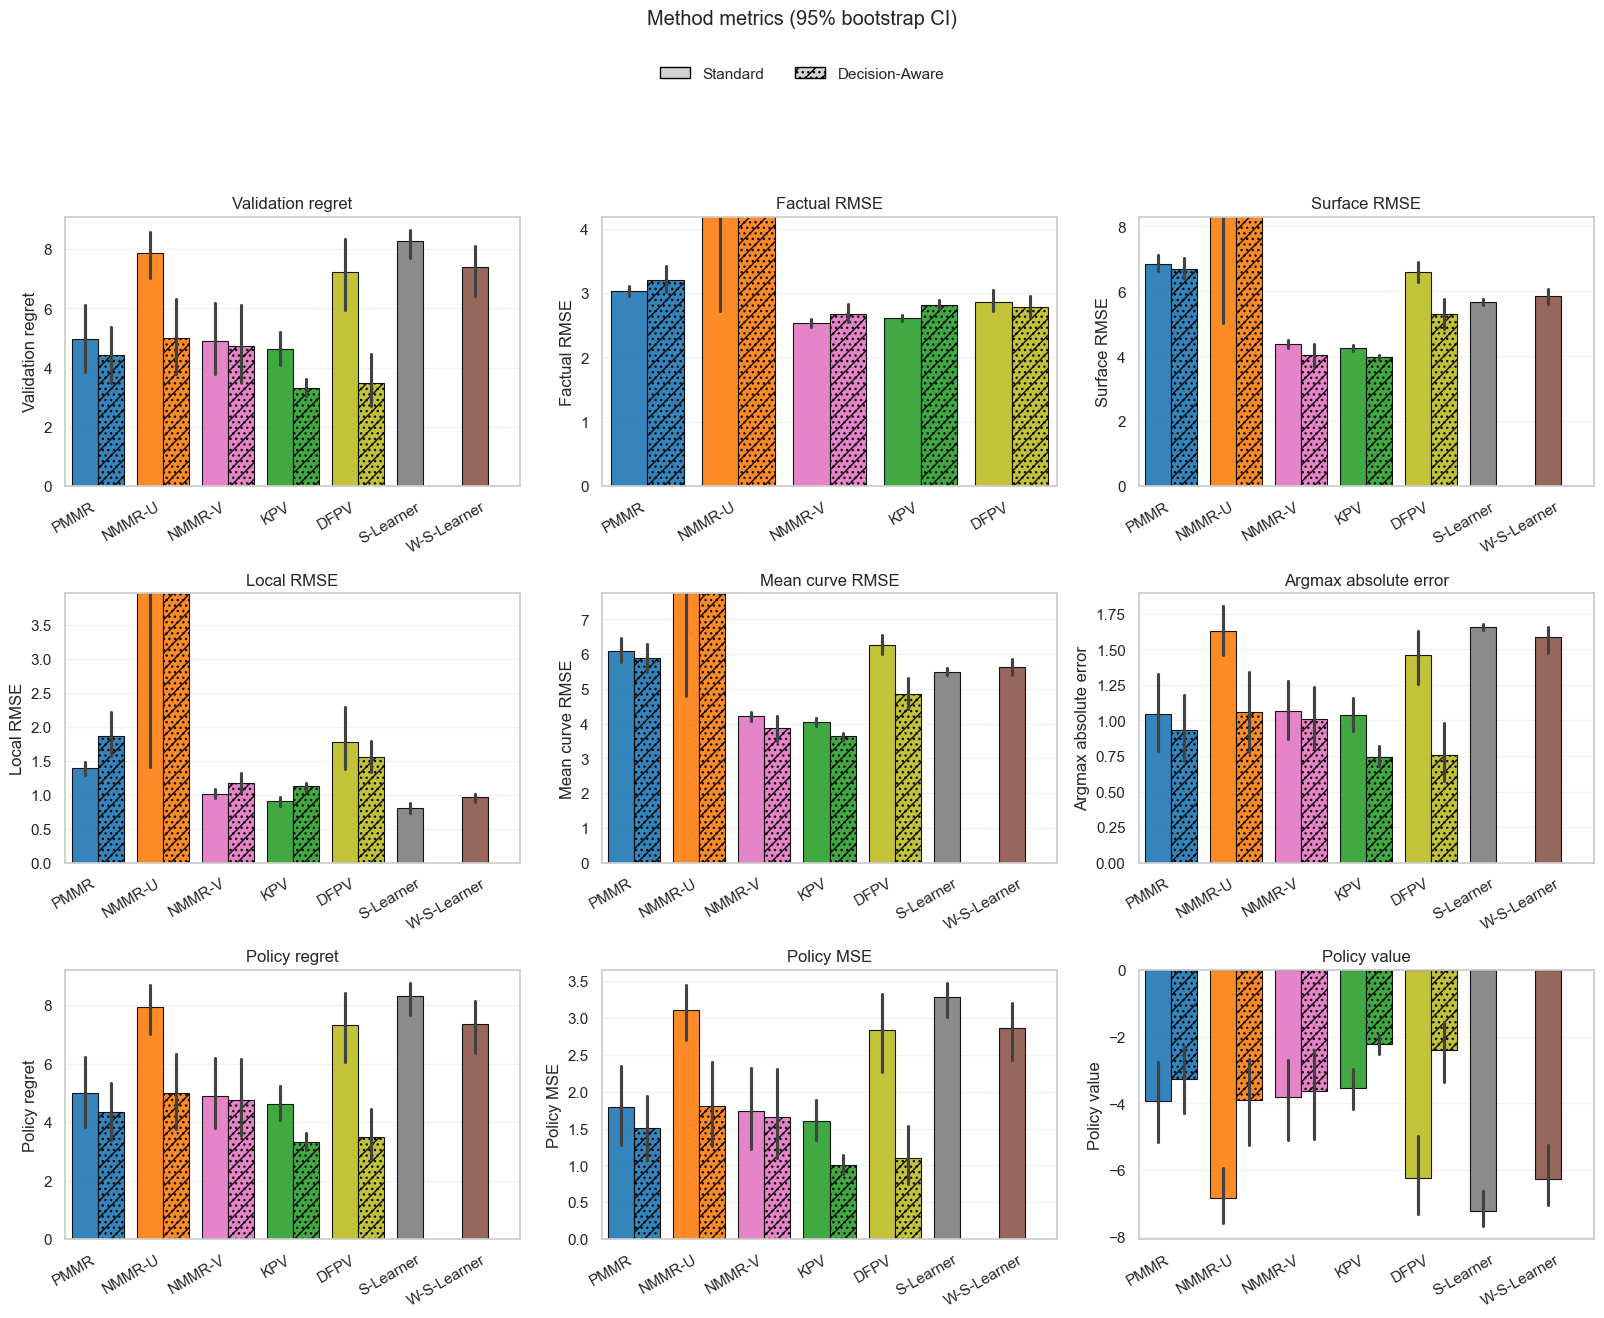

In [6]:
fig = plot_method_metrics_ci_grid_da_grouped(
    metrics_df,
    summary_df,
    metrics_to_use,
    metric_labels=METRIC_LABELS,
    ncols=3,
    pattern_map=DA_PATTERN_MAP,
    confidence=CONFIDENCE,
    n_boot=3000,
    bootstrap_seed=13,
    title=f"Method metrics ({int(CONFIDENCE * 100)}% bootstrap CI)",
)
save_figure(fig, ANALYSIS_DIR / "method_metrics_ci.png")
save_figure(fig, ANALYSIS_DIR / "method_metrics_ci.pdf")
plt.show()



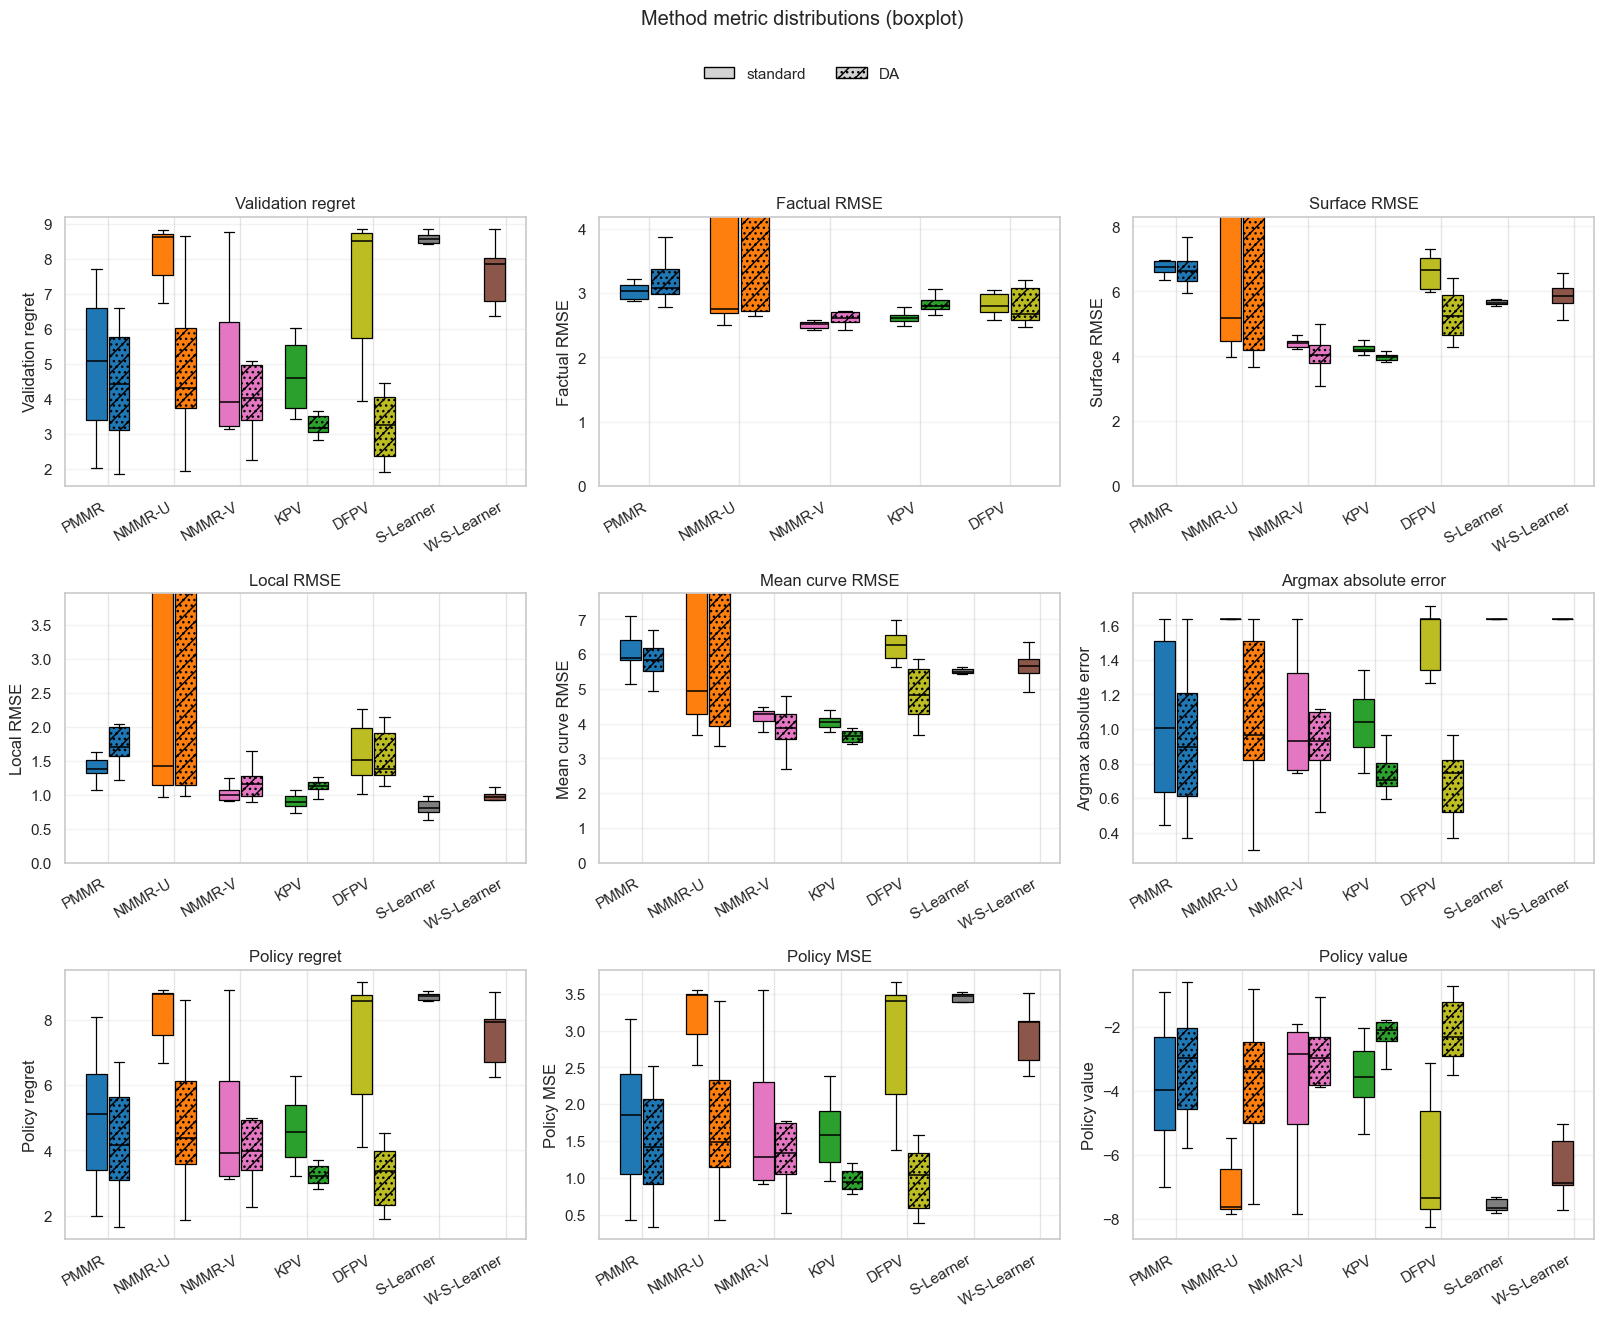

In [7]:
fig = plot_method_metrics_boxplot_grid_da_grouped(
    metrics_df,
    summary_df,
    metrics_to_use,
    metric_labels=METRIC_LABELS,
    ncols=3,
    pattern_map=DA_PATTERN_MAP,
    title="Method metric distributions (boxplot)",
)
save_figure(fig, ANALYSIS_DIR / "method_metrics_boxplot.png")
save_figure(fig, ANALYSIS_DIR / "method_metrics_boxplot.pdf")
plt.show()



C:\Users\Alex\AppData\Local\Temp\ipykernel_30616\2156293916.py:267: UserWarning: The figure layout has changed to tight
  fig.tight_layout(rect=(0, 0, 1, 0.94))


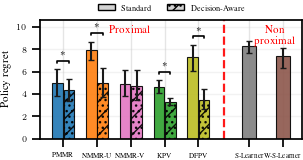

In [8]:
# Single-metric bar plot playground (editable)
import numpy as np
from matplotlib.patches import Patch
from src.analysis.stats import wilcoxon_paired_by_label
NON_PROXIMAL_FAMILIES_BAR = {"S-Learner", "Naive OOSR", "Oracle S-Learner", "Oracle Naive OOSR"}
SINGLE_METRIC_BAR = "regret_causal_marginal"   # e.g. "regret_causal_marginal", "factual_mean_rmse"
SINGLE_BAR_FIGSIZE = (6, 3.5)
SINGLE_BAR_FONT_SIZE = 11
SINGLE_BAR_N_BOOT = 3000
SINGLE_BAR_LEGEND_LOC = "upper center"
SINGLE_BAR_LEGEND_BBOX = (0.5, 1.20)
SINGLE_BAR_SAVE_STEM = f"single_metric_bar_{SINGLE_METRIC_BAR}"
# Extra horizontal space between proximal and non-proximal families.
BAR_GROUP_EXTRA_GAP = 0.5
BAR_SEPARATOR_COLOR = "red"
# Significance controls.
SINGLE_BAR_SIG_ENABLE = True
SINGLE_BAR_SIG_P = 0.05
SINGLE_BAR_SIG_USE_HOLM = True

plot_df_single = _build_metric_plot_df(metrics_df, summary_df, [SINGLE_METRIC_BAR])
metric_df = plot_df_single[plot_df_single["metric"].astype(str) == str(SINGLE_METRIC_BAR)].copy()
if metric_df.empty:
    raise ValueError(f"No data found for metric {SINGLE_METRIC_BAR!r}.")
family_order = _ordered_families_from_methods(metric_df["family"].dropna().unique())
proximal_families = [f for f in family_order if str(f) not in NON_PROXIMAL_FAMILIES_BAR]
non_proximal_families = [f for f in family_order if str(f) in NON_PROXIMAL_FAMILIES_BAR]
family_order = proximal_families + non_proximal_families
color_map = _family_color_map(family_order)
mode_order = ["standard", "DA"]
mode_label_map = {"standard": "Standard", "DA": "Decision-Aware"}
# Manual bar layout so families with only one mode are centered.
family_centers = np.arange(len(family_order), dtype=float)
if proximal_families and non_proximal_families:
    split_idx = len(proximal_families)
    family_centers[split_idx:] += BAR_GROUP_EXTRA_GAP
bar_width = 0.34
SINGLE_BAR_SOLO_WIDTH_MULT = 1.22


plt.rcParams.update({
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.edgecolor": "black",
    "axes.titlecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "legend.labelcolor": "black",
})


# Bootstrap CI helper (percentile interval)
def _bootstrap_ci(values: np.ndarray, n_boot: int, seed: int = 13, alpha: float = 0.05):
    arr = np.asarray(values, dtype=float)
    if arr.size == 0:
        return np.nan, np.nan
    if arr.size == 1:
        return float(arr[0]), float(arr[0])
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, arr.size, size=(int(n_boot), arr.size))
    means = arr[idx].mean(axis=1)
    low = float(np.quantile(means, alpha / 2.0))
    high = float(np.quantile(means, 1.0 - alpha / 2.0))
    return low, high

# Build paired DA/standard arrays per family from original rows.
def _paired_family_values_for_metric(metric_name: str):
    source_rows = summary_df.loc[summary_df["metric"].astype(str) == str(metric_name), ["source_split", "source_metric"]].drop_duplicates()
    if source_rows.empty:
        return {}
    split_name = str(source_rows.iloc[0]["source_split"])
    source_metric = str(source_rows.iloc[0]["source_metric"])
    if source_metric not in metrics_df.columns:
        return {}

    frame = metrics_df.copy()
    if "split" in frame.columns:
        frame = frame[frame["split"].astype(str) == split_name]
    if frame.empty:
        return {}

    frame = frame[[col for col in ["method", "dataset", "seed", "split", source_metric] if col in frame.columns]].copy()
    frame["value"] = pd.to_numeric(frame[source_metric], errors="coerce")
    frame = frame[frame["value"].notna()].copy()
    if frame.empty:
        return {}

    family_mode = frame["method"].astype(str).map(_split_family_mode)
    frame["family"] = [family for family, _ in family_mode]
    frame["mode"] = [mode for _, mode in family_mode]

    paired = {}
    for family in sorted(frame["family"].astype(str).unique()):
        fam = frame[frame["family"].astype(str) == family].copy()
        std = fam[fam["mode"].astype(str) == "standard"].copy()
        da = fam[fam["mode"].astype(str) == "DA"].copy()
        if std.empty or da.empty:
            continue

        keys = [k for k in ["dataset", "seed", "split"] if (k in std.columns and k in da.columns)]
        if keys:
            merged = std[keys + ["value"]].rename(columns={"value": "standard"}).merge(
                da[keys + ["value"]].rename(columns={"value": "DA"}),
                on=keys,
                how="inner",
            )
            da_vals = pd.to_numeric(merged["DA"], errors="coerce").to_numpy(dtype=float)
            std_vals = pd.to_numeric(merged["standard"], errors="coerce").to_numpy(dtype=float)
        else:
            da_vals = pd.to_numeric(da["value"], errors="coerce").to_numpy(dtype=float)
            std_vals = pd.to_numeric(std["value"], errors="coerce").to_numpy(dtype=float)
            n = int(min(da_vals.size, std_vals.size))
            da_vals = da_vals[:n]
            std_vals = std_vals[:n]

        mask = np.isfinite(da_vals) & np.isfinite(std_vals)
        da_vals = da_vals[mask]
        std_vals = std_vals[mask]
        if da_vals.size > 0:
            paired[family] = (da_vals, std_vals)
    return paired

from tueplots import bundles
with plt.rc_context(bundles.icml2024(column='half')):
    fig, ax = plt.subplots()
    fig.patch.set_facecolor("white")
    ax.set_facecolor("white")
    all_upper = []
    family_mode_meta = {}
    for family_idx, family in enumerate(family_order):
        center = family_centers[family_idx]
        family_mask = metric_df["family"].astype(str) == str(family)
        modes_present_family = [m for m in mode_order if np.any(family_mask & (metric_df["mode"].astype(str) == m))]
        if not modes_present_family:
            continue
        if len(modes_present_family) == 1:
            pos_by_mode = {modes_present_family[0]: center}
        else:
            pos_by_mode = {
                modes_present_family[0]: center - bar_width / 2.0,
                modes_present_family[1]: center + bar_width / 2.0,
            }
        family_mode_meta[str(family)] = {}
        for mode in modes_present_family:
            vals = pd.to_numeric(
                metric_df[family_mask & (metric_df["mode"].astype(str) == mode)]["value"],
                errors="coerce",
            ).dropna().to_numpy(dtype=float)
            if vals.size == 0:
                continue
            mean_val = float(np.mean(vals))
            ci_low, ci_high = _bootstrap_ci(vals, n_boot=SINGLE_BAR_N_BOOT, seed=13, alpha=1.0 - CONFIDENCE)
            yerr_low = max(0.0, mean_val - ci_low)
            yerr_high = max(0.0, ci_high - mean_val)
            bar = ax.bar(
                [pos_by_mode[mode]],
                [mean_val],
                width=(bar_width * SINGLE_BAR_SOLO_WIDTH_MULT) if len(modes_present_family) == 1 else (bar_width * 0.92),
                yerr=np.array([[yerr_low], [yerr_high]]),
                capsize=2,
                color=color_map[family],
                edgecolor="black",
                linewidth=0.8,
                alpha=0.9,
            )
            hatch = DA_PATTERN_MAP.get(mode)
            if hatch:
                bar[0].set_hatch(hatch)
            bar_top = mean_val + yerr_high
            all_upper.append(bar_top)
            family_mode_meta[str(family)][str(mode)] = {"x": float(pos_by_mode[mode]), "top": float(bar_top)}

    ax.set_xticks(family_centers)
    ax.set_xticklabels([METHOD_LABELS.get(family, family) for family in family_order], rotation=0
                       , fontsize=5.25
                       )
    # Slightly nudge non-proximal tick labels for readability.
    for tick_label in ax.get_xticklabels():
        text = str(tick_label.get_text()).strip()
        x, y = tick_label.get_position()
        if text == "S-Learner":
            tick_label.set_x(x - 0.08)
        elif text == "W-S-Learner":
            tick_label.set_x(x + 0.08)
    rmse_ymax = _rmse_axis_upper_limit(SINGLE_METRIC_BAR, metric_df)
    if rmse_ymax is not None:
        ax.set_ylim(top=rmse_ymax)
    elif all_upper:
        ax.set_ylim(top=max(all_upper) * 1.08)

    # Wilcoxon significance braces (DA vs standard) without changing bar style.
    if SINGLE_BAR_SIG_ENABLE:
        higher_is_better = bool(METRIC_DIRECTIONS.get(str(SINGLE_METRIC_BAR), False))
        alternative = "greater" if higher_is_better else "less"
        correction = "holm" if bool(SINGLE_BAR_SIG_USE_HOLM) else "uncorrected"
        paired_values = _paired_family_values_for_metric(SINGLE_METRIC_BAR)
        if paired_values:
            sig = wilcoxon_paired_by_label(
                paired_values,
                alpha=float(SINGLE_BAR_SIG_P),
                correction=correction,
                alternative=alternative,
            )
            y0, y1 = ax.get_ylim()
            y_span = max(1e-12, float(y1 - y0))
            brace_h = 0.02 * y_span
            brace_pad = 0.08 * y_span
            used_y = []
            for family in family_order:
                fam_key = str(family)
                result = sig.get(fam_key)
                if not result or not bool(result.get("rejected", False)):
                    continue
                mode_meta = family_mode_meta.get(fam_key, {})
                if "standard" not in mode_meta or "DA" not in mode_meta:
                    continue
                x_std = float(mode_meta["standard"]["x"])
                x_da = float(mode_meta["DA"]["x"])
                x_left, x_right = sorted([x_std, x_da])
                y_base = max(float(mode_meta["standard"]["top"]), float(mode_meta["DA"]["top"])) + brace_pad

                used_y.append(y_base)
                ax.plot([x_left, x_left, x_right, x_right], [y_base - brace_h, y_base, y_base, y_base - brace_h], color="black", linewidth=1.2)
                ax.text(0.5 * (x_left + x_right), y_base + 0.00005 * y_span, "*", ha="center", va="bottom"
                        # , fontsize=SINGLE_BAR_FONT_SIZE + 2
                        , color="black")
            if used_y:
                ax.set_ylim(top=max(ax.get_ylim()[1], max(used_y) + 0.12 * y_span))

    # Visual separator + labels.
    if proximal_families and non_proximal_families:
        split_idx = len(proximal_families)
        x_sep = 0.5 * (family_centers[split_idx - 1] + family_centers[split_idx])
        ax.axvline(x_sep, color=BAR_SEPARATOR_COLOR, linewidth=1.6, alpha=0.9, linestyle='--')
        y_top = ax.get_ylim()[1]
        y_text = y_top * 0.96
        ax.text(x_sep - 2.2, y_text, "Proximal", color=BAR_SEPARATOR_COLOR, ha="right", va="top"
                # , fontsize=max(8, SINGLE_BAR_FONT_SIZE - 1)
                )
        ax.text(x_sep + 1.5, y_text, "Non\nproximal", color=BAR_SEPARATOR_COLOR, ha="center", va="top",
                # fontsize=max(8, SINGLE_BAR_FONT_SIZE - 1)
                )
    ax.set_ylabel(METRIC_LABELS.get(SINGLE_METRIC_BAR, SINGLE_METRIC_BAR)
                  # , fontsize=SINGLE_BAR_FONT_SIZE
                  )
    ax.set_xlabel("")
    ax.tick_params(axis="y"
                   # , labelsize=SINGLE_BAR_FONT_SIZE
                   )
    ax.grid(axis="y", alpha=0.25)
    # Force axis/tick visibility in notebooks with custom themes.
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
    ax.tick_params(axis="both", which="both", colors="black", labelcolor="black", bottom=True, left=True, labelbottom=True, labelleft=True)
    ax.xaxis.label.set_color("black")
    ax.yaxis.label.set_color("black")
    legend_handles = [
        Patch(facecolor="lightgray", edgecolor="black", hatch=DA_PATTERN_MAP.get(mode) or "", label=mode_label_map[mode])
        for mode in mode_order if np.any(metric_df["mode"].astype(str) == mode)
    ]
    if legend_handles:
        ax.legend(handles=legend_handles, loc=SINGLE_BAR_LEGEND_LOC, bbox_to_anchor=SINGLE_BAR_LEGEND_BBOX, ncol=len(legend_handles), frameon=False, title=None
                  # , fontsize=SINGLE_BAR_FONT_SIZE
                  )
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    save_figure(fig, ANALYSIS_DIR / f"{SINGLE_BAR_SAVE_STEM}.png")
    save_figure(fig, ANALYSIS_DIR / f"{SINGLE_BAR_SAVE_STEM}.pdf")
    plt.show()




Summary for metric: global_rmse
family     mode    mean     std  n
  DFPV       DA  5.3010  0.7952 10
  DFPV standard  6.5887  0.5077 10
   KPV       DA  3.9689  0.1101 10
   KPV standard  4.2535  0.1568 10
NMMR-U       DA 32.9431 31.2842 10
NMMR-U standard 12.1601 22.5166 10
NMMR-V       DA  4.0455  0.5656 10
NMMR-V standard  4.3819  0.2045 10
  PMMR       DA  6.7003  0.5366 10
  PMMR standard  6.8507  0.4203 10


C:\Users\Alex\AppData\Local\Temp\ipykernel_30616\4036670074.py:295: UserWarning: The figure layout has changed to tight
  fig.tight_layout(rect=(0, 0, 1, 0.94))


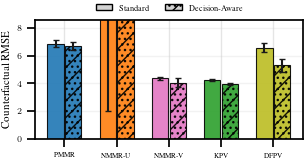

In [70]:
# Single-metric bar plot playground (editable)
import numpy as np
from matplotlib.patches import Patch
from src.analysis.stats import wilcoxon_paired_by_label
NON_PROXIMAL_FAMILIES_BAR = {"S-Learner", "Naive OOSR", "Oracle S-Learner", "Oracle Naive OOSR"}
SINGLE_METRIC_BAR = "global_rmse"   # e.g. "regret_causal_marginal", "factual_mean_rmse"
SINGLE_BAR_FIGSIZE = (6, 3.5)
SINGLE_BAR_FONT_SIZE = 11
SINGLE_BAR_N_BOOT = 3000
SINGLE_BAR_LEGEND_LOC = "upper center"
SINGLE_BAR_LEGEND_BBOX = (0.5, 1.20)
SINGLE_BAR_SAVE_STEM = f"single_metric_bar_{SINGLE_METRIC_BAR}"
# Extra horizontal space between proximal and non-proximal families.
BAR_GROUP_EXTRA_GAP = 0.5
BAR_SEPARATOR_COLOR = "red"
# Significance controls.
SINGLE_BAR_SIG_ENABLE = True
SINGLE_BAR_SIG_P = 0.05
SINGLE_BAR_SIG_USE_HOLM = True
#
RMSE_YMAX_EXCLUDE_FAMILIES = ["NMMR-U", 'Weighted NMMR-U']

plot_df_single = _build_metric_plot_df(metrics_df, summary_df, [SINGLE_METRIC_BAR])

metric_df = plot_df_single[plot_df_single["metric"].astype(str) == str(SINGLE_METRIC_BAR)].copy()
# Only for this plot: hide S-Learner
metric_df = metric_df[metric_df["family"].astype(str) != "S-Learner"].copy()
# Only for this plot: hide S-Learner
metric_df = metric_df[metric_df["family"].astype(str) != "Naive OOSR"].copy()
if metric_df.empty:
    raise ValueError(f"No data found for metric {SINGLE_METRIC_BAR!r}.")
family_order = _ordered_families_from_methods(metric_df["family"].dropna().unique())
proximal_families = [f for f in family_order if str(f) not in NON_PROXIMAL_FAMILIES_BAR]
non_proximal_families = [f for f in family_order if str(f) in NON_PROXIMAL_FAMILIES_BAR]
family_order = proximal_families + non_proximal_families
color_map = _family_color_map(family_order)
mode_order = ["standard", "DA"]
mode_label_map = {"standard": "Standard", "DA": "Decision-Aware"}
# Manual bar layout so families with only one mode are centered.
family_centers = np.arange(len(family_order), dtype=float)
if proximal_families and non_proximal_families:
    split_idx = len(proximal_families)
    family_centers[split_idx:] += BAR_GROUP_EXTRA_GAP
bar_width = 0.34
SINGLE_BAR_SOLO_WIDTH_MULT = 1.22


summary_table = (
    metric_df
    .groupby(["family", "mode"], as_index=False)["value"]
    .agg(mean="mean", std="std", n="count")
)

summary_table["mean"] = summary_table["mean"].round(4)
summary_table["std"] = summary_table["std"].round(4)

print(f"\nSummary for metric: {SINGLE_METRIC_BAR}")
print(summary_table.to_string(index=False))


plt.rcParams.update({
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.edgecolor": "black",
    "axes.titlecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "legend.labelcolor": "black",
})


# Bootstrap CI helper (percentile interval)
def _bootstrap_ci(values: np.ndarray, n_boot: int, seed: int = 13, alpha: float = 0.05):
    arr = np.asarray(values, dtype=float)
    if arr.size == 0:
        return np.nan, np.nan
    if arr.size == 1:
        return float(arr[0]), float(arr[0])
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, arr.size, size=(int(n_boot), arr.size))
    means = arr[idx].mean(axis=1)
    low = float(np.quantile(means, alpha / 2.0))
    high = float(np.quantile(means, 1.0 - alpha / 2.0))
    return low, high

# Build paired DA/standard arrays per family from original rows.
def _paired_family_values_for_metric(metric_name: str):
    source_rows = summary_df.loc[summary_df["metric"].astype(str) == str(metric_name), ["source_split", "source_metric"]].drop_duplicates()
    if source_rows.empty:
        return {}
    split_name = str(source_rows.iloc[0]["source_split"])
    source_metric = str(source_rows.iloc[0]["source_metric"])
    if source_metric not in metrics_df.columns:
        return {}

    frame = metrics_df.copy()
    if "split" in frame.columns:
        frame = frame[frame["split"].astype(str) == split_name]
    if frame.empty:
        return {}

    frame = frame[[col for col in ["method", "dataset", "seed", "split", source_metric] if col in frame.columns]].copy()
    frame["value"] = pd.to_numeric(frame[source_metric], errors="coerce")
    frame = frame[frame["value"].notna()].copy()
    if frame.empty:
        return {}

    family_mode = frame["method"].astype(str).map(_split_family_mode)
    frame["family"] = [family for family, _ in family_mode]
    frame["mode"] = [mode for _, mode in family_mode]

    paired = {}
    for family in sorted(frame["family"].astype(str).unique()):
        fam = frame[frame["family"].astype(str) == family].copy()
        std = fam[fam["mode"].astype(str) == "standard"].copy()
        da = fam[fam["mode"].astype(str) == "DA"].copy()
        if std.empty or da.empty:
            continue

        keys = [k for k in ["dataset", "seed", "split"] if (k in std.columns and k in da.columns)]
        if keys:
            merged = std[keys + ["value"]].rename(columns={"value": "standard"}).merge(
                da[keys + ["value"]].rename(columns={"value": "DA"}),
                on=keys,
                how="inner",
            )
            da_vals = pd.to_numeric(merged["DA"], errors="coerce").to_numpy(dtype=float)
            std_vals = pd.to_numeric(merged["standard"], errors="coerce").to_numpy(dtype=float)
        else:
            da_vals = pd.to_numeric(da["value"], errors="coerce").to_numpy(dtype=float)
            std_vals = pd.to_numeric(std["value"], errors="coerce").to_numpy(dtype=float)
            n = int(min(da_vals.size, std_vals.size))
            da_vals = da_vals[:n]
            std_vals = std_vals[:n]

        mask = np.isfinite(da_vals) & np.isfinite(std_vals)
        da_vals = da_vals[mask]
        std_vals = std_vals[mask]
        if da_vals.size > 0:
            paired[family] = (da_vals, std_vals)
    return paired

from tueplots import bundles
with plt.rc_context(bundles.icml2024(column='half')):
    fig, ax = plt.subplots()
    fig.patch.set_facecolor("white")
    ax.set_facecolor("white")
    all_upper = []
    family_mode_meta = {}
    for family_idx, family in enumerate(family_order):
        center = family_centers[family_idx]
        family_mask = metric_df["family"].astype(str) == str(family)

        modes_present_family = [m for m in mode_order if np.any(family_mask & (metric_df["mode"].astype(str) == m))]
        if not modes_present_family:
            continue
        if len(modes_present_family) == 1:
            pos_by_mode = {modes_present_family[0]: center}
        else:
            pos_by_mode = {
                modes_present_family[0]: center - bar_width / 2.0,
                modes_present_family[1]: center + bar_width / 2.0,
            }
        family_mode_meta[str(family)] = {}
        for mode in modes_present_family:
            vals = pd.to_numeric(
                metric_df[family_mask & (metric_df["mode"].astype(str) == mode)]["value"],
                errors="coerce",
            ).dropna().to_numpy(dtype=float)
            if vals.size == 0:
                continue
            mean_val = float(np.mean(vals))
            ci_low, ci_high = _bootstrap_ci(vals, n_boot=SINGLE_BAR_N_BOOT, seed=13, alpha=1.0 - CONFIDENCE)
            yerr_low = max(0.0, mean_val - ci_low)
            yerr_high = max(0.0, ci_high - mean_val)
            bar = ax.bar(
                [pos_by_mode[mode]],
                [mean_val],
                width=(bar_width * SINGLE_BAR_SOLO_WIDTH_MULT) if len(modes_present_family) == 1 else (bar_width * 0.92),
                yerr=np.array([[yerr_low], [yerr_high]]),
                capsize=2,
                color=color_map[family],
                edgecolor="black",
                linewidth=0.8,
                alpha=0.9,
            )
            hatch = DA_PATTERN_MAP.get(mode)
            if hatch:
                bar[0].set_hatch(hatch)
            bar_top = mean_val + yerr_high
            all_upper.append(bar_top)
            family_mode_meta[str(family)][str(mode)] = {"x": float(pos_by_mode[mode]), "top": float(bar_top)}

    ax.set_xticks(family_centers)
    ax.set_xticklabels([METHOD_LABELS.get(family, family) for family in family_order], rotation=0
                       , fontsize=5.25
                       )
    # Slightly nudge non-proximal tick labels for readability.
    for tick_label in ax.get_xticklabels():
        text = str(tick_label.get_text()).strip()
        x, y = tick_label.get_position()
        if text == "S-Learner":
            tick_label.set_x(x - 0.08)
        elif text == "W-S-Learner":
            tick_label.set_x(x + 0.08)
    rmse_ymax = _rmse_axis_upper_limit(SINGLE_METRIC_BAR, metric_df)
    if rmse_ymax is not None:
        ax.set_ylim(top=rmse_ymax)
    elif all_upper:
        ax.set_ylim(top=max(all_upper) * 1.08)

    # Wilcoxon significance braces (DA vs standard) without changing bar style.
    if SINGLE_BAR_SIG_ENABLE:
        higher_is_better = bool(METRIC_DIRECTIONS.get(str(SINGLE_METRIC_BAR), False))
        alternative = "greater" if higher_is_better else "less"
        correction = "holm" if bool(SINGLE_BAR_SIG_USE_HOLM) else "uncorrected"
        paired_values = _paired_family_values_for_metric(SINGLE_METRIC_BAR)
        if paired_values:
            sig = wilcoxon_paired_by_label(
                paired_values,
                alpha=float(SINGLE_BAR_SIG_P),
                correction=correction,
                alternative=alternative,
            )
            y0, y1 = ax.get_ylim()
            y_span = max(1e-12, float(y1 - y0))
            brace_h = 0.02 * y_span
            brace_pad = 0.08 * y_span
            used_y = []
            for family in family_order:
                fam_key = str(family)
                result = sig.get(fam_key)
                if not result or not bool(result.get("rejected", False)):
                    continue
                mode_meta = family_mode_meta.get(fam_key, {})
                if "standard" not in mode_meta or "DA" not in mode_meta:
                    continue
                x_std = float(mode_meta["standard"]["x"])
                x_da = float(mode_meta["DA"]["x"])
                x_left, x_right = sorted([x_std, x_da])
                y_base = max(float(mode_meta["standard"]["top"]), float(mode_meta["DA"]["top"])) + brace_pad

                used_y.append(y_base)
                #         # , fontsize=SINGLE_BAR_FONT_SIZE + 2
                #         , color="black")
            if used_y:
                ax.set_ylim(top=max(ax.get_ylim()[1], max(used_y) + 0.12 * y_span))

    # Visual separator + labels.
    if proximal_families and non_proximal_families:
        split_idx = len(proximal_families)
        x_sep = 0.5 * (family_centers[split_idx - 1] + family_centers[split_idx])
        ax.axvline(x_sep, color=BAR_SEPARATOR_COLOR, linewidth=1.6, alpha=0.9, linestyle='--')
        y_top = ax.get_ylim()[1]
        y_text = y_top * 0.96
        ax.text(x_sep - 2.2, y_text, "Proximal", color=BAR_SEPARATOR_COLOR, ha="right", va="top"
                # , fontsize=max(8, SINGLE_BAR_FONT_SIZE - 1)
                )
        ax.text(x_sep + 1.5, y_text, "Non\nproximal", color=BAR_SEPARATOR_COLOR, ha="center", va="top",
                # fontsize=max(8, SINGLE_BAR_FONT_SIZE - 1)
                )
    ax.set_ylabel(METRIC_LABELS.get(SINGLE_METRIC_BAR, SINGLE_METRIC_BAR)
                  # , fontsize=SINGLE_BAR_FONT_SIZE
                  )
    ax.set_xlabel("")
    ax.tick_params(axis="y"
                   # , labelsize=SINGLE_BAR_FONT_SIZE
                   )
    ax.grid(axis="y", alpha=0.25)
    # Force axis/tick visibility in notebooks with custom themes.
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
    ax.tick_params(axis="both", which="both", colors="black", labelcolor="black", bottom=True, left=True, labelbottom=True, labelleft=True)
    ax.xaxis.label.set_color("black")
    ax.yaxis.label.set_color("black")
    legend_handles = [
        Patch(facecolor="lightgray", edgecolor="black", hatch=DA_PATTERN_MAP.get(mode) or "", label=mode_label_map[mode])
        for mode in mode_order if np.any(metric_df["mode"].astype(str) == mode)
    ]
    if legend_handles:
        ax.legend(handles=legend_handles, loc=SINGLE_BAR_LEGEND_LOC, bbox_to_anchor=SINGLE_BAR_LEGEND_BBOX, ncol=len(legend_handles), frameon=False, title=None
                  # , fontsize=SINGLE_BAR_FONT_SIZE
                  )
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    save_figure(fig, ANALYSIS_DIR / f"{SINGLE_BAR_SAVE_STEM}.png")
    save_figure(fig, ANALYSIS_DIR / f"{SINGLE_BAR_SAVE_STEM}.pdf")
    plt.show()



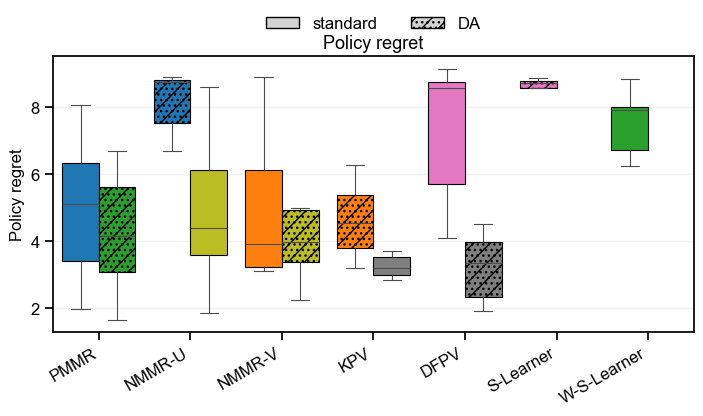

In [10]:
# Single-metric boxplot playground (editable)
import numpy as np
import seaborn as sns
from matplotlib.patches import Patch, PathPatch
SINGLE_METRIC_BOX = "regret_causal_marginal"   # e.g. "regret_causal_marginal", "factual_mean_rmse"
SINGLE_BOX_FIGSIZE = (7.2, 4.8)
SINGLE_BOX_FONT_SIZE = 12
SINGLE_BOX_SHOW_FLIERS = False
SINGLE_BOX_LEGEND_LOC = "upper center"
SINGLE_BOX_LEGEND_BBOX = (0.5, 1.20)
SINGLE_BOX_SAVE_STEM = f"single_metric_boxplot_{SINGLE_METRIC_BOX}"
plot_df_single = _build_metric_plot_df(metrics_df, summary_df, [SINGLE_METRIC_BOX])
metric_df = plot_df_single[plot_df_single["metric"].astype(str) == str(SINGLE_METRIC_BOX)].copy()
if metric_df.empty:
    raise ValueError(f"No data found for metric {SINGLE_METRIC_BOX!r}.")
family_order = _ordered_families_from_methods(metric_df["family"].dropna().unique())
color_map = _family_color_map(family_order)
mode_order = ["standard", "DA"]
present_modes = [mode for mode in mode_order if mode in set(metric_df["mode"].astype(str))]
mode_cycle = present_modes or ["standard"]
fig, ax = plt.subplots(figsize=SINGLE_BOX_FIGSIZE)
ax.set_facecolor("white")
sns.boxplot(
    data=metric_df,
    x="family",
    y="value",
    hue="mode",
    order=family_order,
    hue_order=mode_order,
    dodge=True,
    linewidth=0.8,
    showfliers=bool(SINGLE_BOX_SHOW_FLIERS),
    ax=ax,
)
expected_boxes = len(family_order) * len(mode_cycle)
box_patches = [patch for patch in ax.patches if isinstance(patch, PathPatch)]
if len(box_patches) >= expected_boxes:
    box_patches = box_patches[:expected_boxes]
for idx_patch, patch in enumerate(box_patches):
    family_idx = idx_patch // len(mode_cycle)
    if family_idx >= len(family_order):
        break
    mode = mode_cycle[idx_patch % len(mode_cycle)]
    family = family_order[family_idx]
    patch.set_facecolor(color_map[family])
    patch.set_edgecolor("black")
    hatch = DA_PATTERN_MAP.get(mode)
    if hatch:
        patch.set_hatch(hatch)
tick_positions = np.asarray(ax.get_xticks(), dtype=float)
ax.set_xticks(tick_positions)
ax.set_xticklabels([METHOD_LABELS.get(family, family) for family in family_order], rotation=30, ha="right", fontsize=SINGLE_BOX_FONT_SIZE)
rmse_ymax = _rmse_axis_upper_limit(SINGLE_METRIC_BOX, metric_df)
if rmse_ymax is not None:
    ax.set_ylim(bottom=0.0, top=rmse_ymax)
ax.set_title(METRIC_LABELS.get(SINGLE_METRIC_BOX, SINGLE_METRIC_BOX), fontsize=SINGLE_BOX_FONT_SIZE + 1)
ax.set_ylabel(METRIC_LABELS.get(SINGLE_METRIC_BOX, SINGLE_METRIC_BOX), fontsize=SINGLE_BOX_FONT_SIZE)
ax.set_xlabel("")
ax.tick_params(axis="y", labelsize=SINGLE_BOX_FONT_SIZE)
ax.grid(axis="y", alpha=0.25)
legend = ax.get_legend()
if legend is not None:
    legend.remove()

# Force axis/tick visibility in notebooks with custom themes.
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
ax.tick_params(axis="both", which="both", colors="black", labelcolor="black", bottom=True, left=True, labelbottom=True, labelleft=True)
ax.xaxis.label.set_color("black")
ax.yaxis.label.set_color("black")
ax.title.set_color("black")

legend_handles = [
    Patch(facecolor="lightgray", edgecolor="black", hatch=DA_PATTERN_MAP.get(mode) or "", label=mode)
    for mode in mode_order if mode in set(metric_df["mode"].astype(str))
]
if legend_handles:
    ax.legend(handles=legend_handles, loc=SINGLE_BOX_LEGEND_LOC, bbox_to_anchor=SINGLE_BOX_LEGEND_BBOX, ncol=len(legend_handles), frameon=False, title=None, fontsize=SINGLE_BOX_FONT_SIZE)
fig.tight_layout(rect=(0, 0, 1, 0.94))
save_figure(fig, ANALYSIS_DIR / f"{SINGLE_BOX_SAVE_STEM}.png")
save_figure(fig, ANALYSIS_DIR / f"{SINGLE_BOX_SAVE_STEM}.pdf")
plt.show()



## Aggregated Global Curves

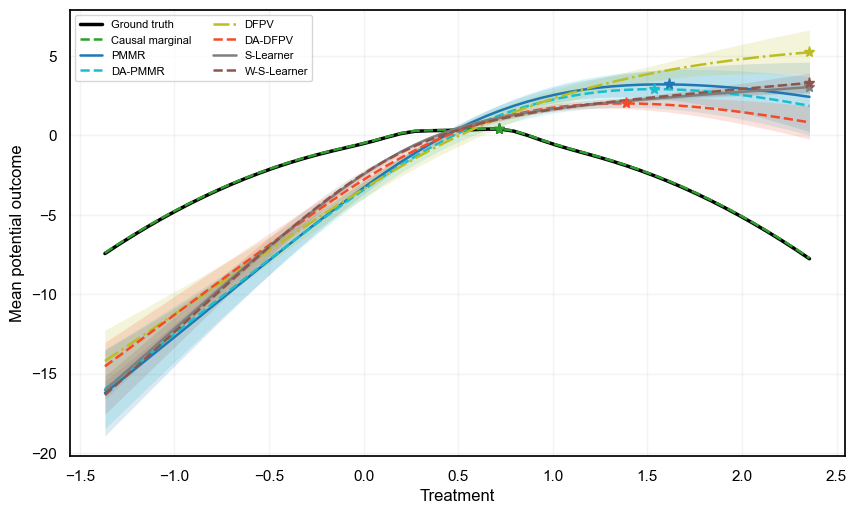

In [11]:
global_methods = ordered_existing_methods(
    global_curves_df.loc[global_curves_df["curve_type"] == "prediction", "method"].unique()
)

GLOBAL_METHODS = [
    "PMMR",
    "Weighted PMMR",
    "S-Learner",
    "Naive OOSR",
    "DFPV",
    "Weighted DFPV"
]

# Select predictor head used for global curves to avoid interleaving artifacts.
GLOBAL_CURVE_PREDICTOR_TYPES = ("mean_or_primary",)
GLOBAL_CURVE_SEPARATE_PREDICTOR_TYPES = False
# Toggle reference curves for global plot.
GLOBAL_REF_SHOW_GROUND_TRUTH = True
GLOBAL_REF_SHOW_CAUSAL_MARGINAL = True
GLOBAL_REF_SHOW_PROXY_CONDITIONED = False
GLOBAL_REFERENCE_VISIBILITY = {
    "ground_truth_oracle_conditioned": GLOBAL_REF_SHOW_GROUND_TRUTH,
    "causal_marginal": GLOBAL_REF_SHOW_CAUSAL_MARGINAL,
    "proxy_conditioned": GLOBAL_REF_SHOW_PROXY_CONDITIONED,
}
GLOBAL_MARK_CURVE_MAXIMA = True

fig = plot_global_curves(
     global_curves_df,
     methods=GLOBAL_METHODS,
     predictor_types=GLOBAL_CURVE_PREDICTOR_TYPES,
     separate_predictor_types=GLOBAL_CURVE_SEPARATE_PREDICTOR_TYPES,
     reference_visibility=GLOBAL_REFERENCE_VISIBILITY,
     mark_curve_maxima=GLOBAL_MARK_CURVE_MAXIMA,
     method_order=METHOD_ORDER,
     labels=METHOD_LABELS,
     colors=METHOD_COLORS,
     linestyles=METHOD_LINESTYLES,
     confidence=CONFIDENCE,
     show_ci=True,
     figsize=(10, 5.8),
 )
save_figure(fig, ANALYSIS_DIR / "global_curves_ci.png")
save_figure(fig, ANALYSIS_DIR / "global_curves_ci.pdf")
plt.show()


## Patient-Specific Surfaces

These figures are reconstructed from the saved `patient_curves.csv` files. Change `SURFACE_SEED`, `PATIENT_RANK`, and `SURFACE_METHODS` without retraining any model.

Surface methods:
['PMMR', 'Weighted PMMR']
curve_type: ground_truth_causal
ground_truth_causal
curve_type: associational
associational
PMMR
Weighted PMMR


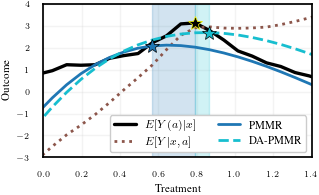

In [54]:
SURFACE_SEED = 5
PATIENT_RANK = 43

available_surface_methods = [
    method for method in patient_curves_df.loc[patient_curves_df["curve_type"] == "prediction", "method"].dropna().unique()
]

SURFACE_METHODS = [
    "PMMR",
    "Weighted PMMR",
]
# Toggle reference curves for patient surfaces.
SURFACE_REF_SHOW_GROUND_TRUTH = True
SURFACE_REF_SHOW_ASSOCIATIONAL = True
SURFACE_REF_SHOW_PROXY_CONDITIONED = False
SURFACE_REF_SHOW_ORACLE_CONDITIONED = False
SURFACE_REFERENCE_VISIBILITY = {
    "ground_truth_causal": SURFACE_REF_SHOW_GROUND_TRUTH,
    "associational": SURFACE_REF_SHOW_ASSOCIATIONAL,
    "proxy_conditioned": SURFACE_REF_SHOW_PROXY_CONDITIONED,
    "oracle_conditioned": SURFACE_REF_SHOW_ORACLE_CONDITIONED,
}
SURFACE_MARK_CURVE_MAXIMA = True

print("Surface methods:")
print(SURFACE_METHODS)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"

plt.rcParams.update({
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.edgecolor": "black",
    "axes.titlecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "legend.labelcolor": "black",
})

from tueplots import bundles

with plt.rc_context(bundles.icml2024(column='half')):
    fig = plot_patient_surface_from_table(
        patient_curves_df,
        seed=SURFACE_SEED,
        patient_rank=PATIENT_RANK,
        methods=SURFACE_METHODS,
        reference_visibility=SURFACE_REFERENCE_VISIBILITY,
        labels=METHOD_LABELS,
        colors=METHOD_COLORS,
        linestyles=METHOD_LINESTYLES,
        mark_curve_maxima=SURFACE_MARK_CURVE_MAXIMA,
    )
    fig.axes[0].set_xlim(0.0, 1.4)
    fig.axes[0].set_ylim(-3, 4)
    save_figure(fig, ANALYSIS_DIR / f"patient_surface_seed_{SURFACE_SEED}_rank_{PATIENT_RANK}.png")
    save_figure(fig, ANALYSIS_DIR / f"patient_surface_seed_{SURFACE_SEED}_rank_{PATIENT_RANK}.pdf")
    plt.show()

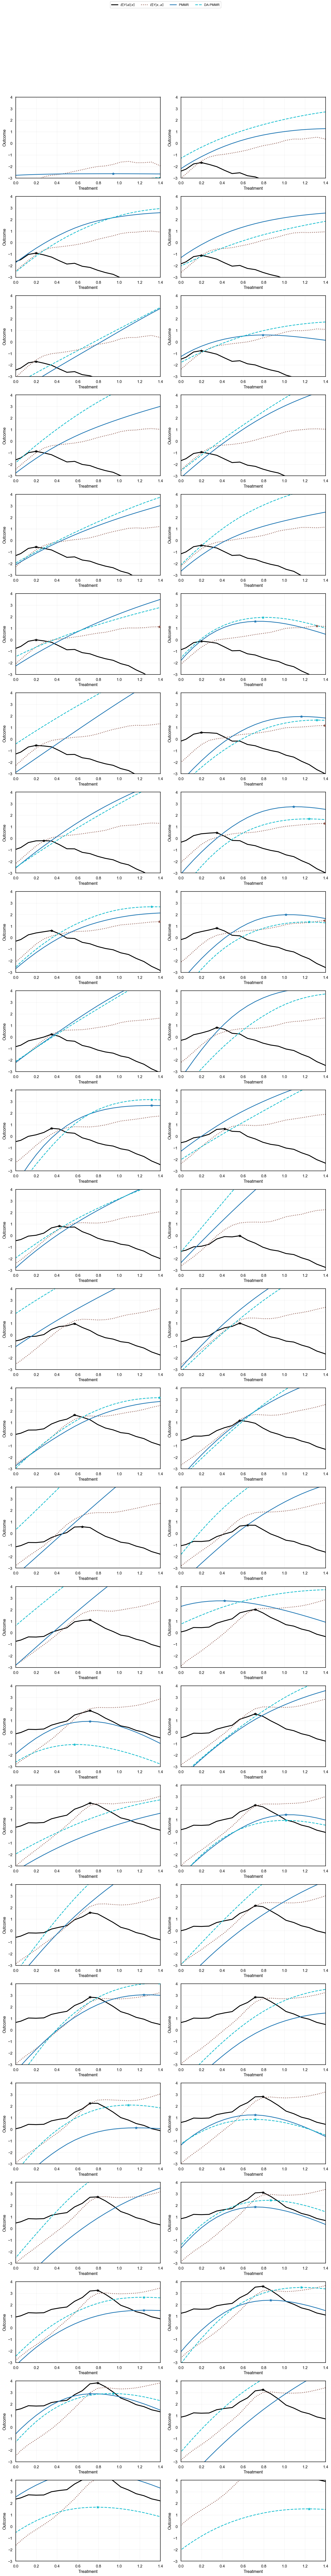

In [13]:
GALLERY_RANKS = list(range(50))

fig = plot_patient_surface_gallery_from_table(
    patient_curves_df,
    seed=SURFACE_SEED,
    patient_ranks=GALLERY_RANKS,
    methods=SURFACE_METHODS,
    reference_visibility=SURFACE_REFERENCE_VISIBILITY,
    labels=METHOD_LABELS,
    colors=METHOD_COLORS,
    linestyles=METHOD_LINESTYLES,
    mark_curve_maxima=SURFACE_MARK_CURVE_MAXIMA,
    ncols=2,
 )
save_figure(fig, ANALYSIS_DIR / f"patient_surface_gallery_seed_{SURFACE_SEED}.png")
save_figure(fig, ANALYSIS_DIR / f"patient_surface_gallery_seed_{SURFACE_SEED}.pdf")
plt.show()

## Non-Parametric Statistical Tests

Oracle methods are excluded from the statistical comparison. For each metric, the paired block is `(dataset, seed)`. If a single dataset is loaded, this is equivalent to pairing by seed. The baseline is selected automatically as the best average non-oracle method for each metric.

In [14]:
candidate_test_methods = ordered_existing_methods(metrics_df["method"].unique())
TEST_METHODS = non_oracle_methods(candidate_test_methods)
TEST_METRICS = metrics_to_use

print("Methods included in statistical tests:")
print(TEST_METHODS)

tests = run_statistical_tests(
    metrics_df,
    TEST_METRICS,
    split=DEFAULT_SPLIT,
    methods=TEST_METHODS,
    metric_directions=METRIC_DIRECTIONS,
    alpha=ALPHA,
    block_cols=("dataset", "seed"),
)

print_statistical_tables(tests, alpha=ALPHA, tablefmt="grid", methods=TEST_METHODS)
written = export_analysis_tables(
    ANALYSIS_DIR,
    metric_summary=summary_df,
    publication_table=publication_table,
    tests=tests,
    test_methods=TEST_METHODS,
)
written

Methods included in statistical tests:
['PMMR', 'Weighted PMMR', 'NMMR-U', 'Weighted NMMR-U', 'NMMR-V', 'Weighted NMMR-V', 'KPV', 'Weighted KPV', 'DFPV', 'Weighted DFPV', 'S-Learner', 'Naive OOSR']

Friedman omnibus tests
+------------------------------+------------+-------------+--------------+--------------------+----------------------+--------------------+
| metric                       |   n_blocks |   n_methods | baseline     | higher_is_better   |   friedman_statistic |   friedman_p_value |
+==============================+============+=============+==============+====================+======================+====================+
| val_regret                   |         10 |          12 | Weighted KPV | False              |              62.9534 |        2.6089e-09  |
+------------------------------+------------+-------------+--------------+--------------------+----------------------+--------------------+
| factual_mean_rmse            |         10 |          10 | NMMR-V       | Fal

{'metric_summary_ci': WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/wu2024_article/analysis/seeds_1_10/metric_summary_ci.csv'),
 'publication_metric_table': WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/wu2024_article/analysis/seeds_1_10/publication_metric_table.csv'),
 'friedman_omnibus': WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/wu2024_article/analysis/seeds_1_10/friedman_omnibus.csv'),
 'friedman_posthoc': WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/wu2024_article/analysis/seeds_1_10/friedman_posthoc.csv'),
 'wilcoxon': WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/wu2024_article/analysis/seeds_1_10/wilcoxon.csv'),
 'friedman_posthoc_holm_table': WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inferen

In [15]:
friedman_posthoc_table = statistical_test_table(tests["friedman_posthoc"], alpha=ALPHA, methods=TEST_METHODS)
wilcoxon_table = statistical_test_table(tests["wilcoxon"], alpha=ALPHA, methods=TEST_METHODS)

display(tests["friedman_omnibus"])
display(friedman_posthoc_table)
display(wilcoxon_table)

,metric,n_blocks,n_methods,baseline,higher_is_better,friedman_statistic,friedman_p_value
0,val_regret,10,12,Weighted KPV,False,62.953431,2.608904e-09
1,factual_mean_rmse,10,10,NMMR-V,False,54.567273,1.472483e-08
2,global_rmse,10,12,Weighted KPV,False,74.707692,1.542190e-11
3,local_rmse,10,12,S-Learner,False,78.584615,2.769507e-12
4,mean_curve_rmse,10,12,Weighted KPV,False,69.076923,1.829176e-10
5,mean_curve_argmax_abs_error,10,12,Weighted KPV,False,61.106139,5.773145e-09
6,regret_causal_marginal,10,12,Weighted KPV,False,61.905812,4.095275e-09
7,policy_mse_causal_marginal,10,12,Weighted KPV,False,62.706933,2.901219e-09
8,policy_value_causal_marginal,10,12,Weighted KPV,True,62.252451,3.528131e-09


method,PMMR,Weighted PMMR,NMMR-U,Weighted NMMR-U,NMMR-V,Weighted NMMR-V,KPV,Weighted KPV,DFPV,Weighted DFPV,S-Learner,Naive OOSR
metric,,,,,,,,,,,,
factual_mean_rmse,<1e-3,<1e-3,0.002,<1e-3,1.000* (baseline),0.313*,0.367*,0.002,0.004,0.013,NaN,NaN
global_rmse,<1e-3,<1e-3,0.002,<1e-3,0.251*,0.914*,0.793*,1.000* (baseline),<1e-3,0.006,0.003,<1e-3
local_rmse,<1e-3,<1e-3,<1e-3,<1e-3,0.288*,0.038,0.990*,0.038,<1e-3,<1e-3,1.000* (baseline),0.716*
mean_curve_argmax_abs_error,0.386*,0.754*,<1e-3,0.240*,0.382*,0.382*,0.386*,1.000* (baseline),0.003,1.000*,<1e-3,<1e-3
mean_curve_rmse,<1e-3,<1e-3,0.002,<1e-3,0.218*,0.771*,0.645*,1.000* (baseline),<1e-3,0.012,<1e-3,<1e-3
policy_mse_causal_marginal,0.307*,0.793*,<1e-3,0.205*,0.307*,0.314*,0.314*,1.000* (baseline),<1e-3,1.000*,<1e-3,<1e-3
policy_value_causal_marginal,0.307*,0.716*,<1e-3,0.174*,0.307*,0.309*,0.307*,1.000* (baseline),<1e-3,1.000*,<1e-3,<1e-3
regret_causal_marginal,0.360*,0.875*,<1e-3,0.280*,0.355*,0.360*,0.355*,1.000* (baseline),<1e-3,1.000*,<1e-3,<1e-3
val_regret,0.327*,0.875*,<1e-3,0.240*,0.307*,0.401*,0.327*,1.000* (baseline),<1e-3,1.000*,<1e-3,<1e-3


method,PMMR,Weighted PMMR,NMMR-U,Weighted NMMR-U,NMMR-V,Weighted NMMR-V,KPV,Weighted KPV,DFPV,Weighted DFPV,S-Learner,Naive OOSR
metric,,,,,,,,,,,,
factual_mean_rmse,0.010,0.010,0.010,0.010,1.000* (baseline),0.010,0.010,0.010,0.010,0.010,NaN,NaN
global_rmse,0.012,0.012,0.012,0.015,0.012,0.492*,0.012,1.000* (baseline),0.012,0.012,0.012,0.012
local_rmse,0.012,0.012,0.012,0.012,0.012,0.012,0.049,0.012,0.012,0.012,1.000* (baseline),0.012
mean_curve_argmax_abs_error,0.164*,0.193*,0.012,0.164*,0.016,0.164*,0.012,1.000* (baseline),0.016,1.000*,0.012,0.012
mean_curve_rmse,0.012,0.012,0.012,0.012,0.012,0.131*,0.012,1.000* (baseline),0.012,0.012,0.012,0.012
policy_mse_causal_marginal,0.059*,0.129*,0.012,0.093*,0.034,0.129*,0.012,1.000* (baseline),0.012,0.846*,0.012,0.012
policy_value_causal_marginal,0.082*,0.161*,0.012,0.161*,0.034,0.161*,0.012,1.000* (baseline),0.012,0.846*,0.012,0.012
regret_causal_marginal,0.111*,0.161*,0.012,0.161*,0.034,0.161*,0.012,1.000* (baseline),0.012,0.846*,0.012,0.012
val_regret,0.082*,0.129*,0.012,0.122*,0.034,0.129*,0.012,1.000* (baseline),0.012,0.846*,0.012,0.012


## Optional LaTeX Export

In [16]:
(ANALYSIS_DIR / "publication_metric_table.tex").write_text(publication_table.to_latex(escape=False), encoding="utf-8")
friedman_posthoc_table.to_latex(ANALYSIS_DIR / "friedman_posthoc_holm_table.tex", escape=False)
wilcoxon_table.to_latex(ANALYSIS_DIR / "wilcoxon_holm_table.tex", escape=False)
print(f"LaTeX tables written to {ANALYSIS_DIR}")







LaTeX tables written to C:\Users\Alex\CODE\optimal_treatment_proximal_inference\weighted_proximal_oosr\results\wu2024_article\analysis\seeds_1_10
